# Where the goals came from

Notebook 01 established the shift: Jordan's opponent-adjusted strength rose
about 0.7 goals of expected goal difference between 2015 and 2026, the rise came
from **attack** rather than defence (+0.744, 95% CI [+0.238, +1.212]), and no
regional peer matched it. Notebook 02 assembled the squad data and marked its
edges.

This notebook asks the next question: **the extra goals — who scored them, and
how many players did it take?**

Two answers are possible and they mean very different things. If the goals came
from a broad group, Jordan built a better team. If they came from a handful,
Jordan found a few players. The second is more fragile, and it is the one the
data points to.

Everything is on the project's stated window, **2015 onward**, split at
**2022-07-01**. Every difference carries a block-bootstrap interval clustered on
six-month windows, because matches inside a window share opponents, a manager
and a squad.

In [1]:
import sys, json
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "JordanData"))
import viz
viz.use_style()

SQUAD = ROOT / "outputs" / "squad"
START, CUT = pd.Timestamp("2015-01-01"), pd.Timestamp(viz.SPLIT)
rng = np.random.default_rng(41)

mt = pd.read_csv(SQUAD / "match_table.csv", parse_dates=["date"]).sort_values("date")
goals = pd.read_csv(SQUAD / "goals.csv", parse_dates=["date"])
ap = pd.read_csv(SQUAD / "appearances_combined.csv")
ja = ap[ap.squad_id == "3e22f0fa"].copy()
ja["Min"] = pd.to_numeric(ja.Min, errors="coerce")

mt = mt[mt.date >= START].copy()
goals = goals[goals.date >= START].copy()
for d in (mt, goals):
    d["era"] = np.where(d.date < CUT, "pre", "post")
mt["blk"] = mt.date.dt.year * 2 + (mt.date.dt.month > 6)

# A scorer is a player id, never a name -- the same man is transliterated
# several ways across sources (notebook 02, section 5).
gj = goals.dropna(subset=["scorer_player_id"]).copy()
NAMES = ja.dropna(subset=["player_id"]).groupby("player_id").Player.agg(
    lambda s: s.mode().iloc[0])

print(f"window   {mt.date.min().date()} .. {mt.date.max().date()}")
print(f"matches  {mt.era.value_counts().reindex(['pre','post']).to_dict()}")
print(f"goals    {goals.era.value_counts().reindex(['pre','post']).to_dict()}"
      f"   with a scorer id: {len(gj)}")

window   2015-01-04 .. 2026-06-27
matches  {'pre': 98, 'post': 45}
goals    {'pre': 142, 'post': 77}   with a scorer id: 215


## 0. One measure this notebook deliberately does not use

`match_table` carries `gf_above_expected` — goals scored minus the model's
expectation for that fixture. It is tempting as an outcome, and it is the wrong
tool for this question.

The model is refit every six months on data *before* each match, so the residual
measures **how far Jordan beat its own contemporaneous forecast**, not how much
it improved. And because Jordan's attack rose while its opponents got much
stronger, the two effects cancel in the expectation: expected goals-for is
essentially *flat* across the boundary while actual goals-for rises. A team
improving faster than a 730-day half-life can track will show a positive
residual for that reason alone.

So the residual is a statement about the model's lag, and using it here would
answer "how much of the forecast error did these players account for" — a
different question, wearing the same clothes.

In [2]:
print(mt.groupby("era")[["gf", "expected_gf", "gf_above_expected",
                         "strength_at_match"]].mean().round(3).to_string())
print()
print("expected_gf barely moves; the model's own ATTACK estimate is what rose.")
tr = pd.read_csv(ROOT / "outputs" / "jordan_strength_ci.csv", parse_dates=["date"])
sel = tr[tr.date.isin(pd.to_datetime(["2015-01-01", "2022-07-01", "2026-07-01"]))]
print(sel[["date", "attack", "attack_lo", "attack_hi"]].round(3).to_string(index=False))

         gf  expected_gf  gf_above_expected  strength_at_match
era                                                           
post  1.756        1.338              0.417              1.110
pre   1.449        1.376              0.073              0.699

expected_gf barely moves; the model's own ATTACK estimate is what rose.
      date  attack  attack_lo  attack_hi
2015-01-01   0.229      0.018      0.399
2022-07-01   0.370      0.135      0.555
2026-07-01   0.710      0.468      0.866


C:\Users\Marwan\AppData\Local\Temp\ipykernel_10604\4142349783.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(sel[["date", "attack", "attack_lo", "attack_hi"]].round(3).to_string(index=False))


This notebook therefore works in **shares and counts** — how goals were
distributed across players and positions, and how settled the team was. Those
need no expectation at all, so none of what follows depends on the model being
well calibrated.

## 1. The goals came from fewer players

"How many different men scored" is a **species-richness** problem, and richness
rises with sample size whatever the underlying diversity. The post-2022 era has
far fewer goals than the pre era, so the two counts are not comparable as
observed — the smaller sample would show fewer scorers even if nothing changed.

The correction is **rarefaction** (Gotelli & Colwell 2001; Hurlbert 1971):
repeatedly draw the larger era down to the smaller era's size and compare
distributions rather than points. Four measures, from breadth to concentration.

In [3]:
pre_s = gj[gj.era == "pre"].scorer_player_id
post_s = gj[gj.era == "post"].scorer_player_id
n_post = len(post_s)

def profile(s):
    vc = s.value_counts(); p = vc / vc.sum()
    return np.array([len(vc), p.iloc[0], p.head(3).sum(), (p ** 2).sum()])

obs = profile(post_s)
draws = np.array([profile(pre_s.sample(n_post, replace=False,
                                       random_state=int(rng.integers(1e9))))
                  for _ in range(4000)])

LABELS = ["distinct scorers", "top-1 share", "top-3 share", "HHI"]
rows = []
for i, lab in enumerate(LABELS):
    lo, hi = np.percentile(draws[:, i], [2.5, 97.5])
    rows.append({"measure": lab, "post": obs[i], "pre_lo": lo, "pre_hi": hi,
                 "verdict": "outside" if not (lo <= obs[i] <= hi) else "inside"})
rar = pd.DataFrame(rows)
print(f"post: {n_post} goals, {int(obs[0])} scorers")
print(f"pre : {len(pre_s)} goals, {pre_s.nunique()} scorers, rarefied to {n_post}\n")
print(rar.round(3).to_string(index=False))

post: 75 goals, 16 scorers
pre : 140 goals, 32 scorers, rarefied to 75

         measure   post  pre_lo  pre_hi verdict
distinct scorers 16.000  21.000  28.000 outside
     top-1 share  0.253   0.147   0.267  inside
     top-3 share  0.640   0.333   0.480 outside
             HHI  0.153   0.068   0.113 outside


findfont: Failed to find font weight semibold, now using 700.


findfont: Failed to find font weight semibold, now using 700.


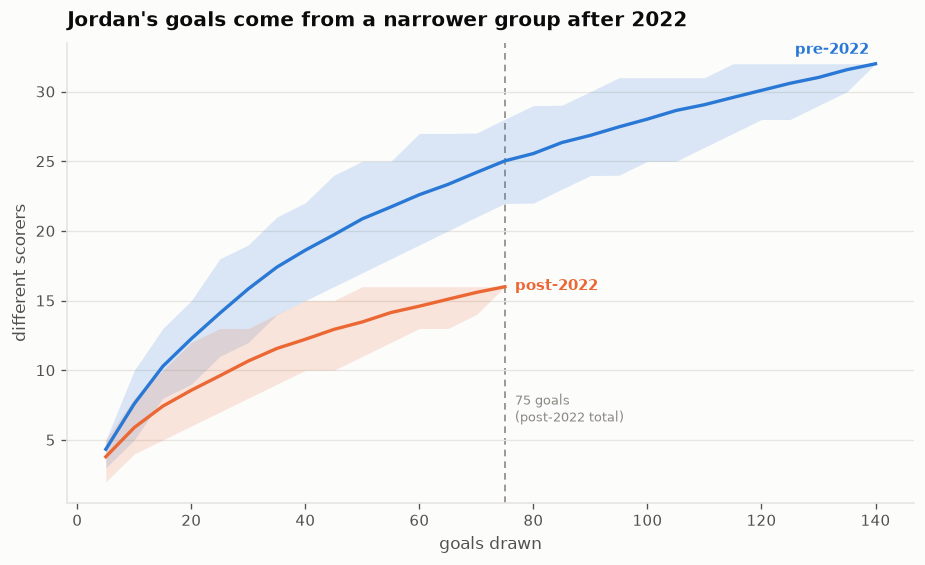

In [4]:
# Rarefaction curve: how many scorers a sample of k goals yields, pre vs post.
def curve(s, ks, reps=400):
    out = []
    for k in ks:
        if k > len(s):
            out.append((np.nan, np.nan, np.nan)); continue
        v = [s.sample(k, replace=False,
                      random_state=int(rng.integers(1e9))).nunique()
             for _ in range(reps)]
        out.append((np.mean(v), *np.percentile(v, [2.5, 97.5])))
    return np.array(out)

ks = np.arange(5, len(pre_s) + 1, 5)
c_pre = curve(pre_s, ks)
ks_post = np.arange(5, n_post + 1, 5)
c_post = curve(post_s, ks_post)

fig, ax = plt.subplots(figsize=(7.6, 4.6))
ax.fill_between(ks, c_pre[:, 1], c_pre[:, 2], color=viz.BLUE, alpha=0.16, lw=0)
ax.plot(ks, c_pre[:, 0], color=viz.BLUE, label="pre-2022")
ax.fill_between(ks_post, c_post[:, 1], c_post[:, 2], color=viz.ORANGE, alpha=0.16, lw=0)
ax.plot(ks_post, c_post[:, 0], color=viz.ORANGE, label="post-2022")
ax.axvline(n_post, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)), zorder=0)
ax.annotate(f"{n_post} goals\n(post-2022 total)", xy=(n_post, 6),
            xytext=(6, 0), textcoords="offset points",
            fontsize=8, color=viz.INK_MUTED, va="bottom")
ax.annotate("pre-2022", xy=(ks[-1], c_pre[-1, 0]), xytext=(-4, 6),
            textcoords="offset points", color=viz.BLUE, fontsize=9,
            ha="right", fontweight="semibold")
ax.annotate("post-2022", xy=(ks_post[-1], c_post[-1, 0]), xytext=(6, -2),
            textcoords="offset points", color=viz.ORANGE, fontsize=9,
            fontweight="semibold")
ax.set_xlabel("goals drawn"); ax.set_ylabel("different scorers")
ax.set_title("Jordan's goals come from a narrower group after 2022")
viz.despine(ax)
plt.show()

The curves separate well before the cut, so this is not an artefact of the eras
being different lengths: **at any common number of goals, the post-2022 era uses
fewer scorers.**

**But it is not one man.** The top-1 share sits *inside* the rarefied interval —
Jordan's leading scorer takes no more of the load than a pre-2022 sample of the
same size would give. The breadth measures move and the single-player measure
does not, which is a narrowing to a small **group**, not a dependence on an
individual. Worth stating plainly, because "one player carries them" is the
popular version of this claim and the data does not support it.

## 2. Who

It is tempting to call this a changing of the guard, and the table below only
half supports that. Two high-volume pre-2022 scorers vanish completely. The
three who take over were **already there** — all of them scoring before 2022,
then scaling up sharply. So it is partly a replacement and partly an emergence,
and the distinction matters: a group that grew into the role is a different
proposition from one that arrived.

In [5]:
tab = (gj.pivot_table(index="scorer_player_id", columns="era",
                      values="match_id", aggfunc="size")
       .reindex(columns=["pre", "post"]).fillna(0).astype(int))
tab["total"] = tab.sum(axis=1)
tab.insert(0, "player", tab.index.map(NAMES))
top = tab.sort_values("total", ascending=False).head(10)
print(top.to_string(index=False))

for e in ("pre", "post"):
    s = gj[gj.era == e].scorer_player_id
    t3 = s.value_counts().head(3)
    print(f"\n{e:4s}  {len(s)} goals, top three = {t3.sum()/len(s):.0%}: "
          + ", ".join(f"{NAMES.get(i, i)} ({c})" for i, c in t3.items()))

             player  pre  post  total
   Hamza Al-Dardour   29     0     29
          Ali Olwan    8    19     27
    Musa Al-Taamari   10    14     24
    Yazan Al-Naimat    5    15     20
       Baha' Faisal   17     0     17
   Mahmoud Al-Mardi    4     5      9
Hassan Abdel-Fattah    6     0      6
      Odai Al-Saify    6     0      6
 Munther Abu Amarah    6     0      6
  Yaseen Al Bakheet    5     0      5

pre   140 goals, top three = 40%: Hamza Al-Dardour (29), Baha' Faisal (17), Musa Al-Taamari (10)

post  75 goals, top three = 64%: Ali Olwan (19), Yazan Al-Naimat (15), Musa Al-Taamari (14)


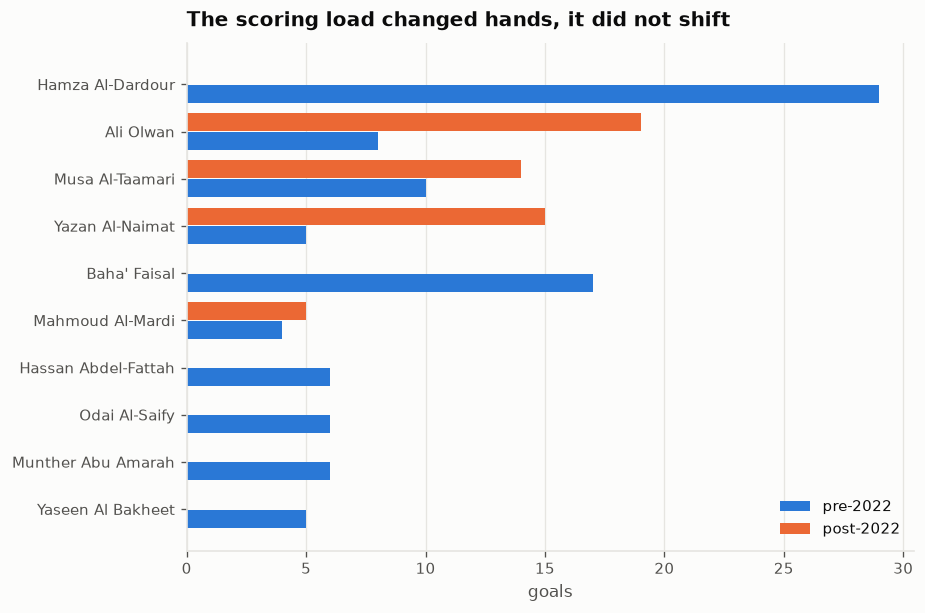

In [6]:
fig, ax = plt.subplots(figsize=(7.6, 5.0))
d = top.iloc[::-1]
y = np.arange(len(d))
ax.barh(y - 0.2, d.pre, height=0.38, color=viz.BLUE, label="pre-2022")
ax.barh(y + 0.2, d.post, height=0.38, color=viz.ORANGE, label="post-2022")
ax.set_yticks(y); ax.set_yticklabels(d.player)
ax.set_xlabel("goals")
ax.set_title("The scoring load changed hands, it did not shift")
ax.legend(loc="lower right")
viz.despine(ax)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
plt.show()

Two patterns, and they should not be blurred together.

**The old top two disappear.** Jordan's leading scorer of the pre-2022 era and
the man third behind him contribute nothing at all afterwards — not reduced
roles, zero goals.

**The new top three were already scoring.** Every one of them appears in the
pre-2022 column, then roughly doubles or triples his output. Al-Taamari in
particular is in the top three of *both* eras, which is why "Jordan replaced its
forwards" would be an overstatement.

So the narrowing in section 1 is not a squad being rebuilt. It is a wide, fairly
flat scoring distribution collapsing onto three players who were already part of
it. Whether that is a team finding its best attackers or a team running out of
alternatives, this data cannot say.

## 3. A narrower group, a more settled team

If the goals come from fewer players, the obvious next question is whether the
*team* also narrowed. Three measures, each of which has to be built carefully
because the naive version is confounded by time.

- **Minutes concentration** — share of all minutes going to the top eleven
  players. Compared at equal match counts.
- **Team familiarity** — the standard measure is pairwise prior appearances
  together (*Journal of Big Data*, 2025). Raw counts accumulate with time and
  FBref's coverage starts in 2011, so both rise for reasons unrelated to Jordan.
  Here it is restricted to a **24-month lookback** and divided by the matches
  available in that window, making it a rate that cannot drift.
- **Appearance rate** — the same treatment for individual starters.

Plus **where the goals came from positionally**, which needs no such correction.

In [7]:
BLOCKS = {e: [d for _, d in mt[mt.era == e].groupby("blk")] for e in ("pre", "post")}
pos_by_match = {m: s.scorer_position.dropna().tolist() for m, s in goals.groupby("match_id")}
mins_by_match = {m: s.groupby("player_id").Min.sum() for m, s in ja.groupby("match_id")}
xi = mt.dropna(subset=["starting_xi"]).copy()
xi["ids"] = xi.starting_xi.map(lambda s: [p["id"] for p in json.loads(s) if p.get("id")])
XI = xi.set_index("match_id")

def mf_share(d):
    v = [p for m in d.match_id for p in pos_by_match.get(m, [])]
    return np.mean([x == "MF" for x in v]) if v else np.nan

def top11(d):
    tot = {}
    for m in d.match_id:
        s = mins_by_match.get(m)
        if s is None:
            continue
        for pid, v in s.items():
            tot[pid] = tot.get(pid, 0) + v
    if not tot:
        return np.nan
    p = pd.Series(tot).sort_values(ascending=False)
    return p.head(11).sum() / p.sum()

# Familiarity and appearance rate depend on the match and the FULL history
# behind it, never on which matches a bootstrap draw happens to pick -- so they
# are computed once per match here, and resampling only averages them.
# Both are divided by the matches available in the 24-month window, making them
# rates: raw counts accumulate with time and FBref's coverage starts in 2011, so
# the unadjusted versions rise for reasons that have nothing to do with Jordan.
fam_rate, caps_rate = {}, {}
for r in xi.itertuples():
    prior = xi[(xi.date >= r.date - pd.Timedelta(days=730)) & (xi.date < r.date)]
    if len(prior) < 15:                # too little history to form a rate
        continue
    pc, cc = {}, {}
    for q in prior.itertuples():
        for pair in combinations(sorted(q.ids), 2):
            pc[pair] = pc.get(pair, 0) + 1
        for i in q.ids:
            cc[i] = cc.get(i, 0) + 1
    pairs = list(combinations(sorted(r.ids), 2))
    fam_rate[r.match_id] = np.mean([pc.get(p, 0) for p in pairs]) / len(prior)
    caps_rate[r.match_id] = np.mean([cc.get(i, 0) for i in r.ids]) / len(prior)

print(f"windowed rates computed for {len(fam_rate)} of {len(xi)} matches with an XI")

def windowed(d, which):
    src = fam_rate if which == "fam" else caps_rate
    v = [src[m] for m in d.match_id if m in src]
    return np.mean(v) if v else np.nan

def block_boot(fn, nb=600):
    """Resample six-month blocks within each era; matches in a window are not
    independent draws, so the block is the unit (Kunsch 1989)."""
    obs = fn(mt[mt.era == "post"]) - fn(mt[mt.era == "pre"])
    vals = []
    for _ in range(nb):
        s = {e: pd.concat([BLOCKS[e][i]
                           for i in rng.integers(0, len(BLOCKS[e]), len(BLOCKS[e]))])
             for e in ("pre", "post")}
        v = fn(s["post"]) - fn(s["pre"])
        if np.isfinite(v):
            vals.append(v)
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return obs, lo, hi

MEASURES = [
    ("midfielder share of goals", mf_share, 600),
    ("minutes: top-11 share", top11, 600),
    ("familiarity rate (pairs)", lambda d: windowed(d, "fam"), 600),
    ("appearance rate (starters)", lambda d: windowed(d, "caps"), 600),
]
res = []
for lab, fn, nb in MEASURES:
    o, lo, hi = block_boot(fn, nb)
    res.append({"measure": lab, "pre": fn(mt[mt.era == "pre"]),
                "post": fn(mt[mt.era == "post"]),
                "diff": o, "lo": lo, "hi": hi,
                "excludes_0": bool(lo > 0 or hi < 0)})
settled = pd.DataFrame(res)
print(settled.round(3).to_string(index=False))

windowed rates computed for 115 of 138 matches with an XI


                   measure   pre  post  diff    lo    hi  excludes_0
 midfielder share of goals 0.217 0.365 0.148 0.039 0.315        True
     minutes: top-11 share 0.443 0.690 0.247 0.135 0.351        True
  familiarity rate (pairs) 0.154 0.371 0.217 0.113 0.337        True
appearance rate (starters) 0.381 0.590 0.209 0.106 0.319        True


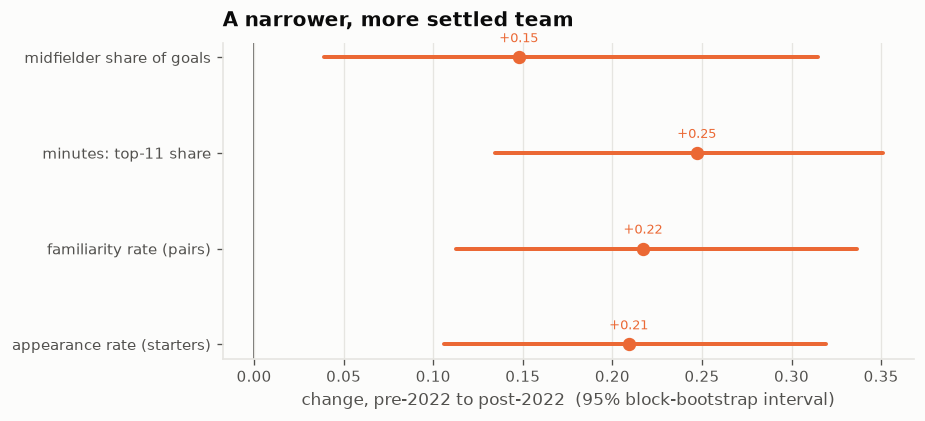

In [8]:
fig, ax = plt.subplots(figsize=(7.6, 3.4))
d = settled.iloc[::-1].reset_index(drop=True)
y = np.arange(len(d))
for i, r in d.iterrows():
    col = viz.ORANGE if r.excludes_0 else viz.INK_MUTED
    ax.plot([r.lo, r.hi], [i, i], color=col, lw=2.4, solid_capstyle="round")
    ax.plot(r["diff"], i, "o", color=col, ms=7, zorder=3)
    ax.annotate(f"{r['diff']:+.2f}", xy=(r["diff"], i), xytext=(0, 9),
                textcoords="offset points", ha="center", fontsize=8, color=col)
ax.axvline(0, color=viz.INK_2, lw=1.0, zorder=0)
ax.set_yticks(y); ax.set_yticklabels(d.measure)
ax.set_xlabel("change, pre-2022 to post-2022  (95% block-bootstrap interval)")
ax.set_title("A narrower, more settled team")
viz.despine(ax)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
plt.show()

All four move the same way and their intervals clear zero: the post-2022 team
gives more of its minutes to fewer players, those players have played together
more recently, and a larger share of the goals comes from midfield.

The last one is worth separating from the rest. The others describe *stability*;
the midfield share describes *shape*. They are consistent with one another but
they are not the same evidence, and the notebook does not treat them as such.

## 4. When the goals happen

A different cut of the same matches: not who scored, but when — and what the
scoreboard said at the time. Reconstructed in `JordanData/match_state.py` from
goal minutes on **both** sides, including the ten Arab Cup matches recovered
from Wikipedia, which FBref does not carry at all.

Coverage is 155 of 174 matches across the whole file and somewhat fewer inside
the 2015 window used here; the cell prints the exact count it works from. The
gap is FBref reports with no event feed, and it is balanced across the two eras
— which it was **not** before the Arab Cup was recovered, when the missing
matches were disproportionately Jordan's best.

In [9]:
ms = pd.read_csv(SQUAD / "match_state.csv", parse_dates=["date"])
ms = ms[(ms.date >= START) & ms.jordan_side.notna()].copy()
ms["era"] = np.where(ms.date < CUT, "pre", "post")
BUCK = ["1-15", "16-30", "31-45", "46-60", "61-75", "76-90"]
f_tot = ms[[f"for_{b}" for b in BUCK]].sum().values
a_tot = ms[[f"against_{b}" for b in BUCK]].sum().values
prof = pd.DataFrame({"window": BUCK,
                     "scored": f_tot / f_tot.sum(),
                     "conceded": a_tot / a_tot.sum()})
print(f"{len(ms)} matches, {int(f_tot.sum())} scored, {int(a_tot.sum())} conceded\n")
print(prof.round(3).to_string(index=False))
print("\nArmatas et al. (2009), all football, 76-90 window: 0.225")

128 matches, 200 scored, 135 conceded

window  scored  conceded
  1-15   0.100     0.067
 16-30   0.180     0.141
 31-45   0.165     0.178
 46-60   0.165     0.111
 61-75   0.155     0.170
 76-90   0.235     0.333

Armatas et al. (2009), all football, 76-90 window: 0.225


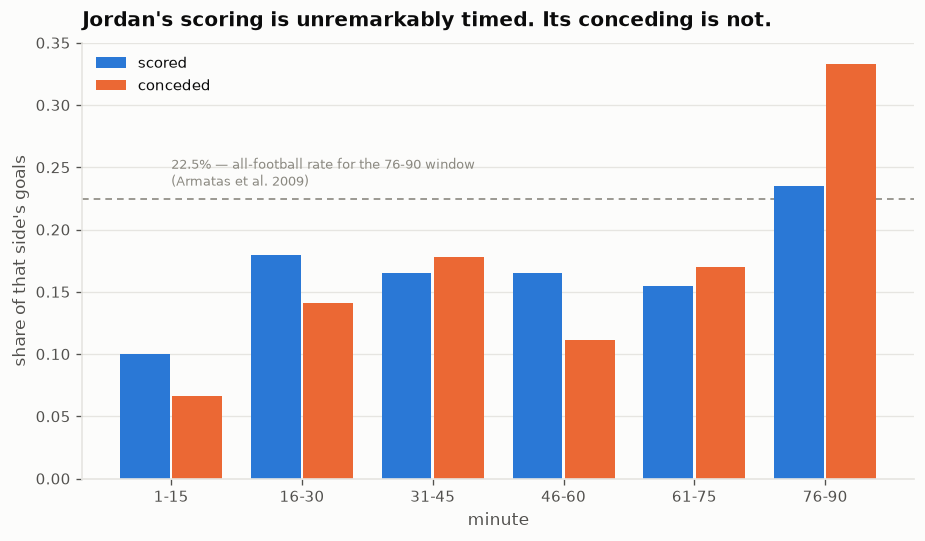

In [10]:
fig, ax = plt.subplots(figsize=(7.6, 4.4))
x = np.arange(len(BUCK))
ax.bar(x - 0.2, prof.scored, width=0.38, color=viz.BLUE, label="scored")
ax.bar(x + 0.2, prof.conceded, width=0.38, color=viz.ORANGE, label="conceded")
ax.axhline(0.225, color=viz.INK_MUTED, lw=1.0, ls=(0, (4, 3)), zorder=0)
ax.annotate("22.5% — all-football rate for the 76-90 window\n(Armatas et al. 2009)",
            xy=(0, 0.225), xytext=(0, 5), textcoords="offset points",
            fontsize=8, color=viz.INK_MUTED, va="bottom")
ax.set_xticks(x); ax.set_xticklabels(BUCK)
ax.set_xlabel("minute"); ax.set_ylabel("share of that side's goals")
ax.set_title("Jordan's scoring is unremarkably timed. Its conceding is not.")
ax.legend(loc="upper left")
viz.despine(ax)
ax.grid(axis="x", visible=False); ax.grid(axis="y", visible=True)
plt.show()

Jordan's own late scoring sits almost exactly on the all-football benchmark —
the attack has no special relationship with the clock. The conceding column is
the outlier: **a third of every goal Jordan concedes arrives in the last fifteen
minutes**, around half again the rate the literature expects.

This is a description of all 155 matches, **not** a change across 2022 — the era
difference in that window does not clear zero. It is a standing feature of this
team over the whole period, and it is the clearest thing in the notebook that
points at something to fix rather than something to celebrate.

## 5. What it isn't

The measures below were built and returned nothing. They are reported because a
null with an interval is a result, and because each one closes off an
explanation that would otherwise stay live.

In [11]:
ms["blk"] = ms.date.dt.year * 2 + (ms.date.dt.month > 6)
ms["margin"] = ms.gf - ms.ga     # before the blocks are cut, or the draws lack it
SB = {e: [d for _, d in ms[ms.era == e].groupby("blk")] for e in ("pre", "post")}

def sboot(fn, nb=1200):
    obs = fn(ms[ms.era == "post"]) - fn(ms[ms.era == "pre"])
    vals = []
    for _ in range(nb):
        s = {e: pd.concat([SB[e][i] for i in rng.integers(0, len(SB[e]), len(SB[e]))])
             for e in ("pre", "post")}
        v = fn(s["post"]) - fn(s["pre"])
        if np.isfinite(v):
            vals.append(v)
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return obs, lo, hi

NULLS = [
    ("share of time leading", lambda d: (d.min_leading / d.match_end).mean()),
    ("share of time trailing", lambda d: (d.min_trailing / d.match_end).mean()),
    ("scores first", lambda d: d.first_goal.eq("for").mean()),
    ("trailed -> avoided defeat", lambda d: d.recovered.dropna().mean()),
    ("win by 3+", lambda d: (d.margin >= 3).mean()),
    ("lose by 3+", lambda d: (d.margin <= -3).mean()),
]
rows = []
for lab, fn in NULLS:
    o, lo, hi = sboot(fn)
    rows.append({"measure": lab, "diff": o, "lo": lo, "hi": hi,
                 "excludes_0": bool(lo > 0 or hi < 0)})
nulls = pd.DataFrame(rows)
print(nulls.round(3).to_string(index=False))

                  measure   diff     lo    hi  excludes_0
    share of time leading -0.007 -0.190 0.125       False
   share of time trailing  0.048 -0.055 0.213       False
             scores first -0.020 -0.295 0.194       False
trailed -> avoided defeat  0.073 -0.133 0.291       False
                win by 3+ -0.030 -0.182 0.102       False
               lose by 3+  0.005 -0.060 0.100       False


In [12]:
# Scoring rate per 90 minutes ACTUALLY SPENT in each state. Both numerator and
# denominator move when a match is resampled, so the rate is what is bootstrapped.
def rate(d, s, direction="gf"):
    m = d[f"min_{s}"].sum()
    return d[f"{direction}_{s}"].sum() / m * 90 if m > 0 else np.nan

for s in ("leading", "level", "trailing"):
    o, lo, hi = sboot(lambda d, ss=s: rate(d, ss))
    a, b = rate(ms[ms.era == "pre"], s), rate(ms[ms.era == "post"], s)
    print(f"  scored while {s:9s} pre {a:.2f}  post {b:.2f}  "
          f"diff {b-a:+.2f}  95% [{lo:+.2f}, {hi:+.2f}]")

# The comparison of interest as a single quantity: does the team push when behind?
def ratio(d):
    lv = rate(d, "level")
    return rate(d, "trailing") / lv if lv > 0 else np.nan

o, lo, hi = sboot(ratio)
print(f"\n  trailing/level ratio  pre {ratio(ms[ms.era=='pre']):.2f}  "
      f"post {ratio(ms[ms.era=='post']):.2f}  diff {o:+.2f}  95% [{lo:+.2f}, {hi:+.2f}]")
print(f"  goals scored while trailing, both eras: "
      f"{int(ms.gf_trailing.sum())} -- the whole basis of this comparison")

  scored while leading   pre 2.43  post 1.96  diff -0.47  95% [-1.49, +0.57]


  scored while level     pre 1.13  post 1.53  diff +0.39  95% [-0.51, +1.05]


  scored while trailing  pre 0.82  post 1.40  diff +0.58  95% [-0.21, +1.31]



  trailing/level ratio  pre 0.72  post 0.92  diff +0.19  95% [-1.01, +0.99]
  goals scored while trailing, both eras: 24 -- the whole basis of this comparison


In [13]:
# The keeper: a complete handover, and no effect on goals conceded
kp = pd.read_csv(SQUAD / "keeper.csv")
kj = kp[kp.squad_id == "3e22f0fa"].merge(
    mt[["match_id", "era", "date", "ga", "expected_ga"]], on="match_id")
kj["above"] = kj.ga - kj.expected_ga
k = (kj.groupby("Player").agg(matches=("match_id", "size"),
                              pre=("era", lambda s: (s == "pre").sum()),
                              post=("era", lambda s: (s == "post").sum()),
                              first=("date", "min"), last=("date", "max"),
                              ga=("ga", "mean"), ga_above_expected=("above", "mean"))
     .sort_values("matches", ascending=False))
k["first"] = k["first"].dt.date
k["last"] = k["last"].dt.date
print("goalkeepers, 8+ matches:")
print(k[k.matches >= 8].round(3).to_string())
print("\ncards per match:", mt.groupby("era").n_cards.mean().round(2).to_dict())

goalkeepers, 8+ matches:
                      matches  pre  post       first        last     ga  ga_above_expected
Player                                                                                    
Yazeed Abulaila            53   18    35  2017-06-01  2026-06-27  1.208              0.020
Amer Shafi                 47   47     0  2015-01-12  2021-02-01  0.894             -0.017
Moataz Yaseen              20   20     0  2015-01-04  2021-09-04  0.650             -0.308
Ahmed Abdel-Sattar         12   12     0  2016-06-05  2021-05-31  0.833              0.119
Abdallah Al-Fakhouri        9    8     1  2018-01-11  2024-11-19  0.889              0.050

cards per match: {'post': 1.39, 'pre': 1.3}


- **Match state.** Time leading, time trailing, scoring first, recovering from
  behind — every interval spans zero. Jordan did not become a team that manages
  the scoreboard differently.
- **Scoring rate by state.** The point estimates are seductive: pre-2022 Jordan
  looks like a front-runner, scoring freely with a lead and *below its own
  level-state rate* when chasing — the opposite of the pattern Lago-Peñas &
  Gómez-López (2014) describe, where teams that go behind take on more of the
  game. Post-2022 looks flatter. But the whole comparison rests on the handful
  of goals Jordan has scored while trailing in eleven years, and the interval on
  the trailing/level ratio is far too wide to support any of it. A good story
  that the data cannot carry.
- **Margins.** Winning and losing heavily happen at the old rates. What changed
  is that matches became higher-scoring overall.
- **The goalkeeper.** The position does change hands — Amer Shafi plays 47
  matches and none after February 2021, and Yazeed Abulaila, who had been
  sharing the role since 2017, takes it over outright. But goals conceded above
  expectation are essentially identical between the two. A plausible mechanism,
  measured and ruled out.
- **Discipline.** Cards per match, unchanged.

Two more, tested elsewhere and excluded here for reasons worth recording:
**substitutions** are confounded by the 2020 five-substitute rule, which lands
two years before the treatment date; **manager** gives 15 spells across the
window and cannot be separated from squad change at this sample size.

## Summary

**Supported** — each with an interval that excludes zero, or a rarefied
comparison that falls outside:

- the goals after 2022 come from a **narrower group** of scorers: fewer distinct
  scorers, higher top-3 share, higher HHI, all outside the rarefied pre-2022
  range at equal sample size
- the team is **more settled**: minutes concentrated in fewer players, and
  starters who have played together more in the preceding two years
- a larger share of goals comes from **midfield**

**True of the whole period, not a change:**

- Jordan concedes **a third of its goals in the last fifteen minutes**, against
  an all-football benchmark of 22.5%

**Not established** — measured, interval spans zero:

- that Jordan relies on **one** player: the top-1 share is ordinary
- any change in match-state behaviour, in the rate of heavy wins or defeats, in
  the goalkeeper's contribution, or in discipline

**Ruled out as the mechanism:** goalkeeping and discipline.

### What this does and does not license

The honest reading is a **coincidence with uncertainty**, which is what this
design can support and no more. Jordan's attack improved; over the same period
the scoring narrowed onto a small group of new players and the team became more
settled. Those things happened together.

They are not shown to cause one another. Squad change, coaching change and
scheduling all move together across mid-2022, there are ~40 matches after it,
and no design here separates them. The one thing worth saying beyond the
association is a **caution rather than a conclusion**: a rise carried by a
narrow group is more fragile than one carried by a broad one, and the top-3
share is the number to watch if the level slips.